See [the documentation](https://ajwheeler.github.io/Korg.jl/stable/install/) for instructions on installing Korg and making it talk to Python.

In [1]:
from juliacall import Main as jl
jl.seval("using Korg")
Korg = jl.Korg
import matplotlib.pyplot as plt
import time
import numpy as np

Detected IPython. Loading juliacall extension. See https://juliapy.github.io/PythonCall.jl/stable/compat/#IPython


This notebook explains the basics of how to use Korg, but you can also see more detailed documentation for any function on the [documentation website](https://ajwheeler.github.io/Korg.jl/stable/API/)

## Read in a linelist (or use a built-in one)

First, load a linelist.  The [`read_linelist`](https://ajwheeler.github.io/Korg.jl/stable/API/#Korg.read_linelist) function, which is automatically exported when you do `using Korg` loads a linelist file (VALD, Kurucz, and MOOG formats accepted), and returns a vector of `Korg.Line` objects.

If you don't have a linelist you want to use, Korg comes with a VALD extract-stellar linelist for the sun that you can use to get started, as well as the APOGEE DR17 and GALAH DR3 linelists.

In [2]:
#lines = Korg.read_linelist("linelist.vald", format="vald")
lines = Korg.get_VALD_solar_linelist() # lines for the Sun from 3000 to 9000 Å
#lines = Korg.get_APOGEE_DR17_linelist() # if you want to do something in the infrared (this is for 15,000 Å - 17,000 Å)
#lines = Korg.get_GALAH_DR3_linelist()

# Create a model atmosphere (via interpolation), or read one in from a file.

Korg can interpolate model atmospheres from the [grid of MARCS atmospheres generated for the Sloan Digital Sky Survey](https://www.sdss4.org/dr17/irspec/apogee-libraries/). 
To do this, use the `interpolate_marcs` function ([documentation](https://ajwheeler.github.io/Korg.jl/stable/API/#Korg.interpolate_marcs)).  It takes 5 arguments: $T_\mathrm{eff}$, $\log g$, \[Fe/H\], \[$\alpha$/Fe\], and \[C/Fe\], but only  $T_\mathrm{eff}$ and $\log g$ are required.

**Important:** in general, you want the abundances of the model atmosphere to match those of the synthesis.  Below, I demonstrate how to do this easilly.

In [3]:
# this generates a model atmosphere for a dwarf with Teff = 5221 K and logg=4.32
dwarf_atm = Korg.interpolate_marcs(5221, 4.32) # we could also provide abundance parameters for non-solar values

Constructing cool dwarf atmosphere interpolator.  This will only happen once per process...


Reading in a MARCS-format model atmosphere from a file is as simple as calling the `read_model_atmosphere` function.

In [4]:
#giant_atm = Korg.read_model_atmosphere("s6000_g+1.0_m0.5_t05_st_z+0.00_a+0.00_c+0.00_n+0.00_o+0.00_r+0.00_s+0.00.mod")

# Synthesizing a spectrum

Now we can synthesize a stellar spectrum, by passing the linelist and atmosphere to `synthesize` function, along with upper and lower wavelengths (in Å). Korg uses wavelengths *in vacuo*, but you can use [`Korg.air_to_vacuum`](https://ajwheeler.github.io/Korg.jl/stable/API/#Korg.air_to_vacuum) and [`Korg.vacuum_to_air`](https://ajwheeler.github.io/Korg.jl/stable/API/#Korg.vacuum_to_air) to convert back and forth. `synthesize` will also do this conversion automatically if you ask it to. See [the documentation](https://ajwheeler.github.io/Korg.jl/stable/API/#Korg.synthesize) for a complete list of optional arguments.
`format_A_X()` returns the solar abundance pattern in the required format.

Julia is just-in-time compiled, which means that the first time in each session you call a method (e.g. `synthesize`, `read_linelist`, or `read_model_atmosphere`), the code will be compiled, which can take several seconds.  Here, we're using `time.process_time` to see how long each call to `synthesize` takes. The first call is kinda slow, with lots of time devoted to compilation. When we call it a second time, it's much faster, because no code needs to be compiled.

In [4]:
# run this cell again to see how much faster it is after precompilation.
t = time.process_time()
sol = Korg.synthesize(dwarf_atm, lines, Korg.format_A_X(0), 4000, 4030)
time.process_time() - t

39.961384308999996

In [5]:
# run this cell again to see how much faster it is after precompilation.
t = time.process_time()
sol = Korg.synthesize(dwarf_atm, lines, Korg.format_A_X(0), 5000, 5030); 
time.process_time() - t

0.45565861800000107

`Korg.synthesize` returns an object containing the spectrum and other useful quantities.
`flux`, `cntm`, and `wavelengths` are exactly what they sound like, and can be accessed like this:

In [6]:
sol.flux
#sol.wavelengths
#sol.cntm

3001-element Vector{Float64}:
 6.283557564305534e14
 6.284147886156152e14
 6.282807591383669e14
 6.282832991529712e14
 6.282891194997861e14
 6.282172319571348e14
 6.280940335778275e14
 6.273519389940059e14
 6.252138249541472e14
 6.203091247193975e14
 ⋮
 6.279031090082669e14
 6.277781635387946e14
 6.274098344488069e14
 6.264591726502655e14
 6.241966689299919e14
 6.197162120950185e14
 6.130006905248241e14
 6.057404228126889e14
 6.018194531355996e14

We can plot them with plt like this:

Text(0, 0.5, 'rectified flux')

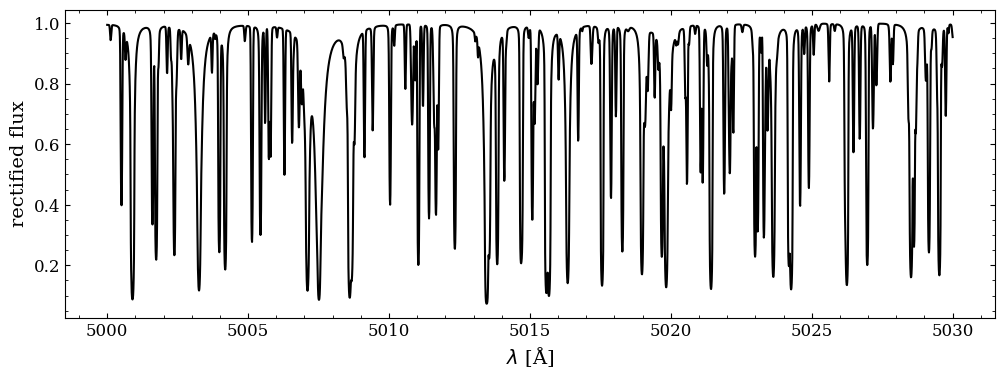

In [7]:
plt.figure(figsize=(12, 4))
plt.plot(sol.wavelengths, np.array(sol.flux) / np.array(sol.cntm), "k-")
plt.xlabel("$\lambda$ [Å]")
plt.ylabel("rectified flux")

## Specifying abundances

Let's synthesize spectra with varied abundances and take a look at the results.
Korg takes in a vector of abundances for all elements from H to U in $A(X)$ format. The `format_A_X` function provies an easy way to do this. The first argument specifies the default `[X/H]` abundance, the second lets you specify the default `[alpha/H]` abundance, and the third lets you specify individual abundances.


In [8]:
metal_poor_A_X = Korg.format_A_X(-0.5) # [M/H] = -1/2
alpha_rich_A_X = Korg.format_A_X(0, 0.5) # all [M/H] = 0, but [alpha/H] = 0.5]
Ni_enriched_A_X = Korg.format_A_X({"Ni": 1.0}) # all [M/H] = 0, except [Ni/H] = 1.0

In order to make sure that the model atmosphere abundances match the synthesis abundances, we pass `A_X` vectors directly to `interpolate_marcs`.

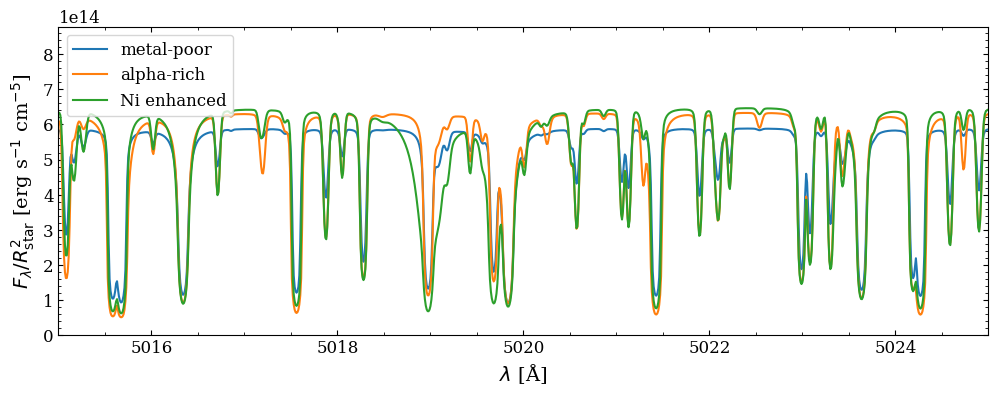

In [9]:
metal_poor_atm = Korg.interpolate_marcs(5221, 4.32, metal_poor_A_X)
metal_poor_sol = Korg.synthesize(metal_poor_atm, lines, metal_poor_A_X, 5015, 5025)

alpha_rich_sol = Korg.interpolate_marcs(5221, 4.32, alpha_rich_A_X)
alpha_rich_sol = Korg.synthesize(alpha_rich_sol, lines, alpha_rich_A_X, 5015, 5025)

Ni_enriched_atm = Korg.interpolate_marcs(5221, 4.32, Ni_enriched_A_X)
Ni_enriched_sol = Korg.synthesize(Ni_enriched_atm, lines, Ni_enriched_A_X, 5015, 5025)

plt.figure(figsize=(12, 4))
plt.plot(metal_poor_sol.wavelengths, metal_poor_sol.flux, label="metal-poor")
plt.plot(alpha_rich_sol.wavelengths, alpha_rich_sol.flux, label="alpha-rich")
plt.plot(Ni_enriched_sol.wavelengths, Ni_enriched_sol.flux, label="Ni enhanced")

plt.xlabel("$\lambda$ [Å]")
plt.ylabel("$F_\lambda/R_\mathrm{star}^2$ [erg s$^{-1}$ cm$^{-5}$]")
plt.xlim(5015, 5025)
plt.ylim(0, plt.ylim()[1]*1.3) # make a little room on top for the legend
plt.legend()

## Other data returned by `synthesize`

`sol.alpha` is a matrix containing the absorption coefficient, $\alpha$ at each wavelength and atmospheric layer.  We can plot $\alpha$ as a function of wavelength like this.

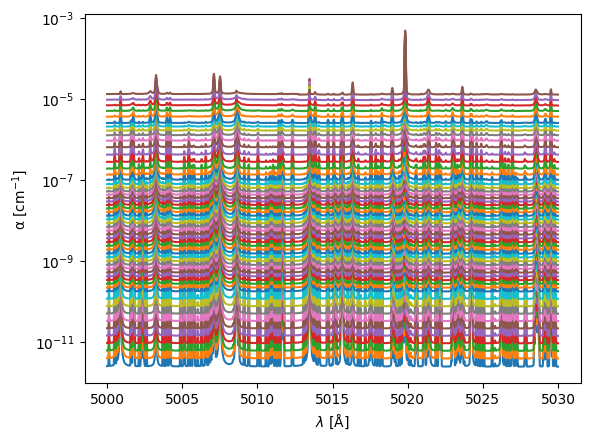

In [11]:
plt.plot(sol.wavelengths, np.array(sol.alpha).transpose())
plt.yscale("log")
plt.xlabel("$\lambda$ [Å]")
plt.ylabel("α [cm$^{-1}$]");

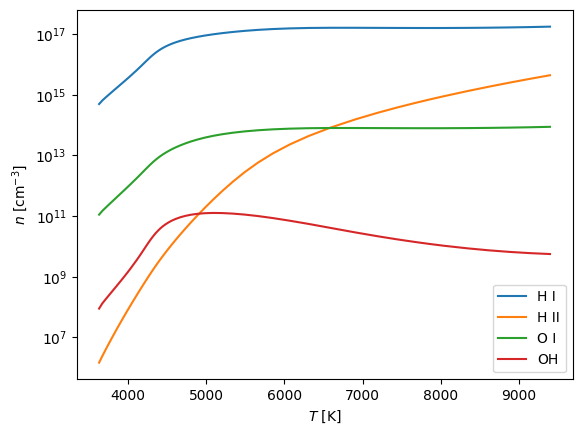

In [12]:
temps = Korg.get_temps(dwarf_atm)

# These strings represent different species. Below, we pass them to Korg.Species to construct a Species object.
for spec in ["H I", "H II", "O I", "OH"]:
    plt.plot(temps, sol.number_densities[Korg.Species(spec)], label=spec)

plt.legend()
plt.yscale("log")
plt.xlabel("$T$ [K]")
plt.ylabel("$n$ [cm$^{-3}$]");